# Figure 4 Supplement

Supplementary and sensitivity analyses for the spatial organization of O3 laminar profiles. This notebook reads cached full-cohort or explicitly labeled pilot outputs; it does not rebuild geodesic pairs, resample profiles, or modify pipeline data. Depth follows the canonical pial-to-white convention.

In [12]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale')
FIGURE_DIR = ROOT / 'figures'
REAL_DIR = ROOT / 'figure4_real/cohort'
WITHIN_REGION_DIR = ROOT / 'figure4_within_region'
WITHIN_WHOLE_CORTEX_DIR = ROOT / 'figure4_within_region_whole_cortex'
ACQUISITION_NULL_DIR = ROOT / 'figure4_acquisition_sampling_full325_fwhm0/cohort'
WHOLE_PROFILE_NULL_DIR = ROOT / 'figure4_whole_profile_permutation_pilot20/cohort'
LONG_RANGE_DIR = ROOT / 'figure4_long_range_platform_full_cohort'
LAMINAR_SHAPE_DIR = ROOT / 'figure4_common_laminar_shape_pilot20'
DK_DIR = ROOT / 'figure4_dk_all_pairs_region_balanced/cohort'
ICO5_K_DIR = ROOT / 'figure4_ico5_k_convergence_pilot20/cohort'
ICO5_K20_DIR = ROOT / 'figure4_ico5_k_convergence_pilot20/cohort_k20'
ICO5_K25_DIR = ROOT / 'figure4_ico5_k_convergence_pilot20/cohort_k25'
ICO5_K30_DIR = ROOT / 'figure4_ico5_k_convergence_pilot20/cohort_k30'
ICO5_K_PILOT5_DIR = ROOT / 'figure4_ico5_k_convergence_pilot20/cohort_pilot5'
ICO5_K_PAIR_DIR = ROOT / 'figure4_ico5_k_convergence_pilot20/pairs'

def show_image(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path)))

print(f'Results root: {ROOT}')

Results root: /mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale


## S1. Fixed-anchor coverage

Coverage diagnostics for the fixed fsaverage anchors used by Figure 4. Counts are descriptive and do not define the independent statistical unit.

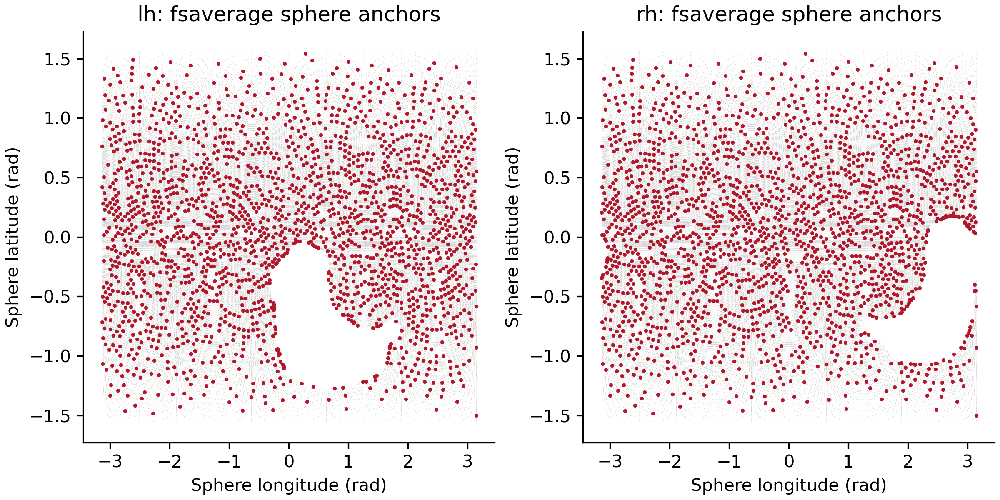

,hemisphere,n_analysis_vertices,n_anchors,anchor_fraction,nearest_anchor_angle_deg_median,nearest_anchor_angle_deg_q95,nearest_anchor_angle_deg_max
0,lh,149953,2048,0.013658,1.766212,3.576128,6.70868
1,rh,149926,2048,0.013660,1.765557,3.598550,6.70868


In [13]:
show_image(REAL_DIR / 'figure4_anchor_coverage_sphere.png')
display(pd.read_csv(REAL_DIR / 'figure4_anchor_coverage_summary.csv'))

## S2. Bilateral within-region profiles

The main regional heatmap caps profile dissimilarity at 0.35. The first diagnostic below restores the full 0–0.90 range for every affected region. The second figure shows all 34 bilateral DK regions as small multiples; curves are group medians and shaded bands are subject-level IQRs.

{'status': 'complete',
 'subjects_expected': 325,
 'subjects_completed': 325,
 'subjects_missing': [],
 'bilateral_regions': 34,
 'distance_bins': 15,
 'minimum_subject_count': 260,
 'minimum_valid_pairs_per_subject_region_bin': 20,
 'formal_cells': 488,
 'total_cells': 510,
 'fixed_directed_pairs_total': 770106,
 'main_dissimilarity_vmax': 0.35,
 'cells_clipped_in_main_dissimilarity_heatmap': 66,
 'regions_with_clipped_cells': ['entorhinal',
  'temporalpole',
  'inferiortemporal',
  'caudalanteriorcingulate',
  'parahippocampal',
  'rostralanteriorcingulate',
  'medialorbitofrontal'],
 'aggregation': 'within-region pair -> hemisphere x anchor x 2-mm-bin median -> bilateral subject x DK-region median -> group median/IQR',
 'pair_count_note': 'fixed_directed_pair_count is the number of anchor-neighbor rows in the reusable fsaverage Figure 4A pair table; valid_pair_count_total sums retained profile-pair observations across subjects'}

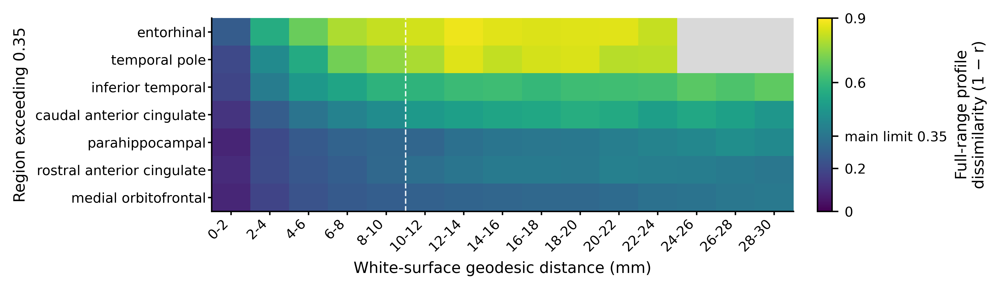

,heterogeneity_class,within_class_quantile_target,dk_region,heterogeneity_0_10
0,Low,0.2,superiorparietal,0.073365
1,Low,0.5,parstriangularis,0.081183
2,Low,0.8,precentral,0.087778
3,Intermediate,0.2,caudalmiddlefrontal,0.097401
4,Intermediate,0.5,precuneus,0.099342
5,Intermediate,0.8,bankssts,0.121313
6,High,0.2,lateralorbitofrontal,0.199003
7,High,0.5,rostralanteriorcingulate,0.226916
8,High,0.8,fusiform,0.239412


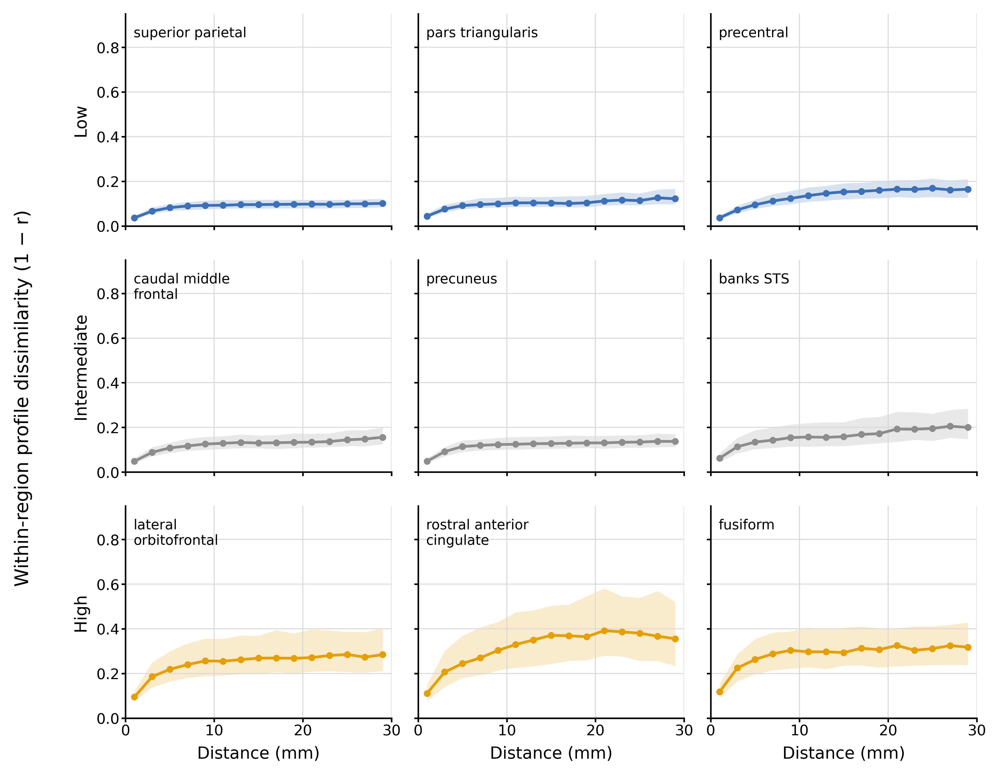

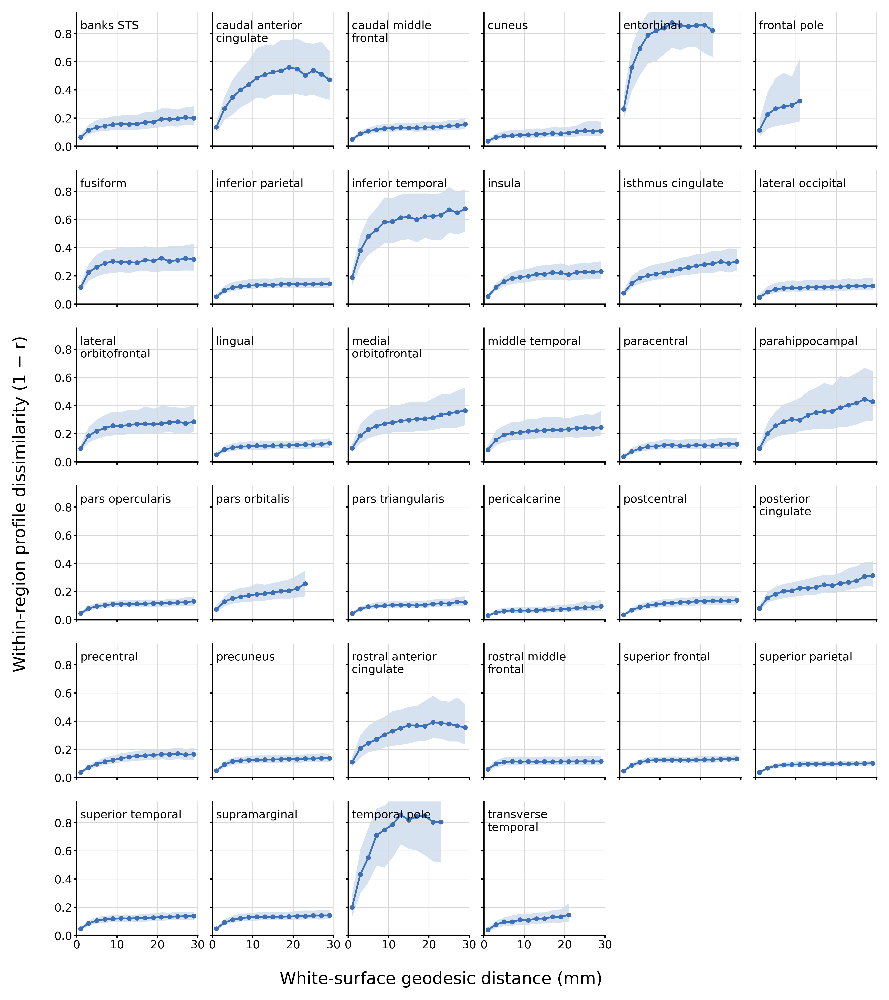

In [14]:
regional_status = json.loads((WITHIN_REGION_DIR / 'figure4A2_status.json').read_text())
display(regional_status)
show_image(FIGURE_DIR / 'Figure4A2_high_dissimilarity_full_range.png')
representatives = pd.read_csv(WITHIN_REGION_DIR / 'figure4A2_representative_regions.csv')
display(representatives[[
    'heterogeneity_class', 'within_class_quantile_target',
    'dk_region', 'heterogeneity_0_10',
]])
show_image(FIGURE_DIR / 'Figure4A2_representative_within_region_curves.png')
show_image(FIGURE_DIR / 'Figure4A2_all_within_region_small_multiples.png')

## S3. Whole-cortex curve restricted to within-region pairs

Only pairs with identical endpoint DK labels are retained. Aggregation is pair → anchor × distance-bin median → bilateral whole-cortex subject median → group median/IQR; pair counts never weight the estimate.

{'status': 'complete',
 'subjects_expected': 325,
 'subjects_completed': 325,
 'subjects_missing': [],
 'fixed_within_region_pair_count': 770106,
 'aggregation': 'within-region pair -> hemisphere x anchor x 2-mm-bin median -> subject median across bilateral cortex -> group median/IQR',
 'pair_count_weighting': False,
 'bootstrap_iterations': 10000}

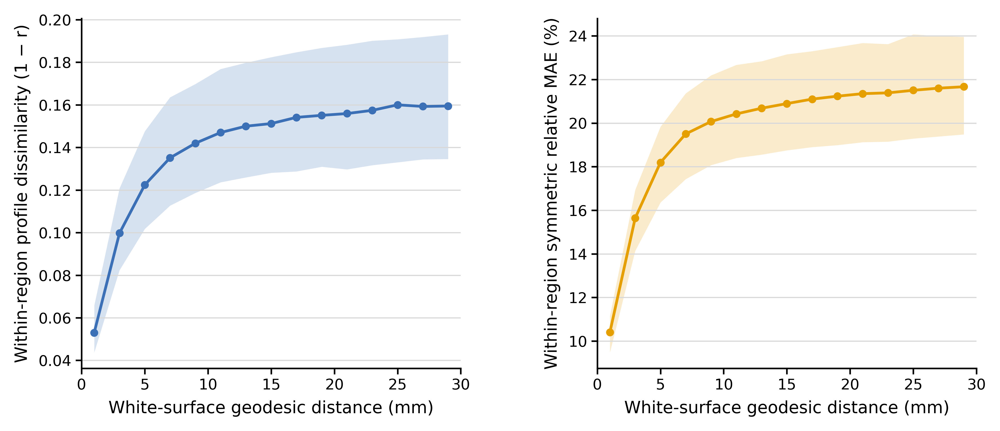

,distance_bin_index,distance_bin,distance_bin_center_mm,n_subjects,anchor_count_total,anchor_count_median_subject,valid_pair_count_total,valid_pair_count_median_subject,region_count_median_subject,profile_dissimilarity_median,...,profile_mae_bootstrap_ci95_low,profile_mae_bootstrap_ci95_high,symmetric_relative_mae_pct_median,symmetric_relative_mae_pct_q25,symmetric_relative_mae_pct_q75,symmetric_relative_mae_pct_bootstrap_ci95_low,symmetric_relative_mae_pct_bootstrap_ci95_high,fixed_pair_count,fixed_anchor_count,fixed_region_count
0,0,0-2,1,325,1296510,4010.0,23905637,74004.0,34.0,0.053029,...,0.000075,0.000078,10.405787,9.477178,11.149868,10.195094,10.555093,75399,4096,34
1,1,2-4,3,325,1296490,4010.0,23516350,72799.0,34.0,0.099742,...,0.000112,0.000117,15.638546,14.136885,16.935833,15.237773,15.886889,74736,4096,34
2,2,4-6,5,325,1296467,4010.0,22182343,68691.0,34.0,0.122394,...,0.000130,0.000135,18.192715,16.358021,19.832777,17.726044,18.495083,70627,4096,34
3,3,6-8,7,325,1296450,4010.0,20919076,64764.0,34.0,0.135116,...,0.000139,0.000144,19.501217,17.430555,21.365448,19.061264,19.775921,66691,4096,34
4,4,8-10,9,325,1296417,4010.0,19553014,60550.0,34.0,0.141973,...,0.000143,0.000149,20.069342,18.071918,22.188419,19.749298,20.429066,62365,4096,34
5,5,10-12,11,325,1296389,4010.0,18319075,56734.0,34.0,0.147012,...,0.000146,0.000151,20.419168,18.397726,22.670414,20.051020,20.673615,58438,4096,34
6,6,12-14,13,325,1295314,4007.0,17101991,52970.0,34.0,0.149991,...,0.000147,0.000153,20.680510,18.552578,22.835703,20.353205,21.064936,54532,4093,34
7,7,14-16,15,325,1293312,4000.0,15820412,48992.0,34.0,0.151213,...,0.000149,0.000156,20.892904,18.749680,23.155098,20.536999,21.306671,50459,4088,34
8,8,16-18,17,325,1291614,3995.0,14657388,45400.0,34.0,0.154131,...,0.000150,0.000156,21.098953,18.897650,23.298349,20.720675,21.460527,46717,4083,34
9,9,18-20,19,325,1287926,3984.0,13535239,41926.0,34.0,0.155082,...,0.000151,0.000157,21.233089,18.989370,23.484720,20.845594,21.592485,43126,4071,34


In [15]:
within_status = json.loads(
    (WITHIN_WHOLE_CORTEX_DIR / 'figure4_within_region_whole_cortex_status.json').read_text()
)
within_group = pd.read_csv(
    WITHIN_WHOLE_CORTEX_DIR / 'figure4_within_region_whole_cortex_group_summary.csv'
)
display(within_status)
show_image(FIGURE_DIR / 'Figure4A_within_region_whole_cortex.png')
display(within_group)

## S4. Acquisition-and-sampling null sensitivity

Supplementary absolute-difference and subject-level AUC displays for the full-cohort DWI-grid Gaussian FWHM 0-mm null. The synthetic signal is generated in the native DWI grid, sampled through the real O3 coordinates with trilinear interpolation, and matched to the subject-specific laminar mean/covariance.

,psf_fwhm_mm,n_subjects,bootstrap_replicates,bootstrap_seed,auc_residual_local_excess_0_10_mm_median,auc_residual_local_excess_0_10_mm_q25,auc_residual_local_excess_0_10_mm_q75,auc_residual_local_excess_0_10_mm_bootstrap_ci_low,auc_residual_local_excess_0_10_mm_bootstrap_ci_high,auc_residual_local_excess_0_10_mm_positive_fraction,mean_residual_local_excess_0_10_median,mean_residual_local_excess_0_10_q25,mean_residual_local_excess_0_10_q75,mean_residual_local_excess_0_10_bootstrap_ci_low,mean_residual_local_excess_0_10_bootstrap_ci_high,mean_residual_local_excess_0_10_positive_fraction
0,0.0,325,10000,20261020,0.357061,0.292378,0.438436,0.342367,0.365806,0.996923,0.035706,0.029238,0.043844,0.034237,0.036556,0.996923


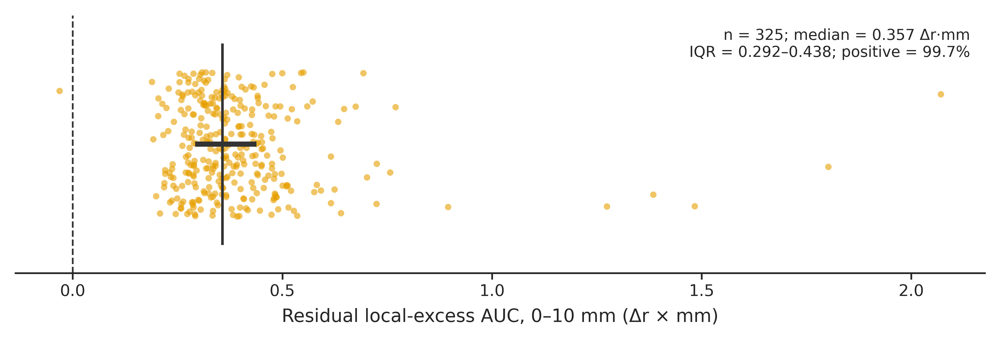

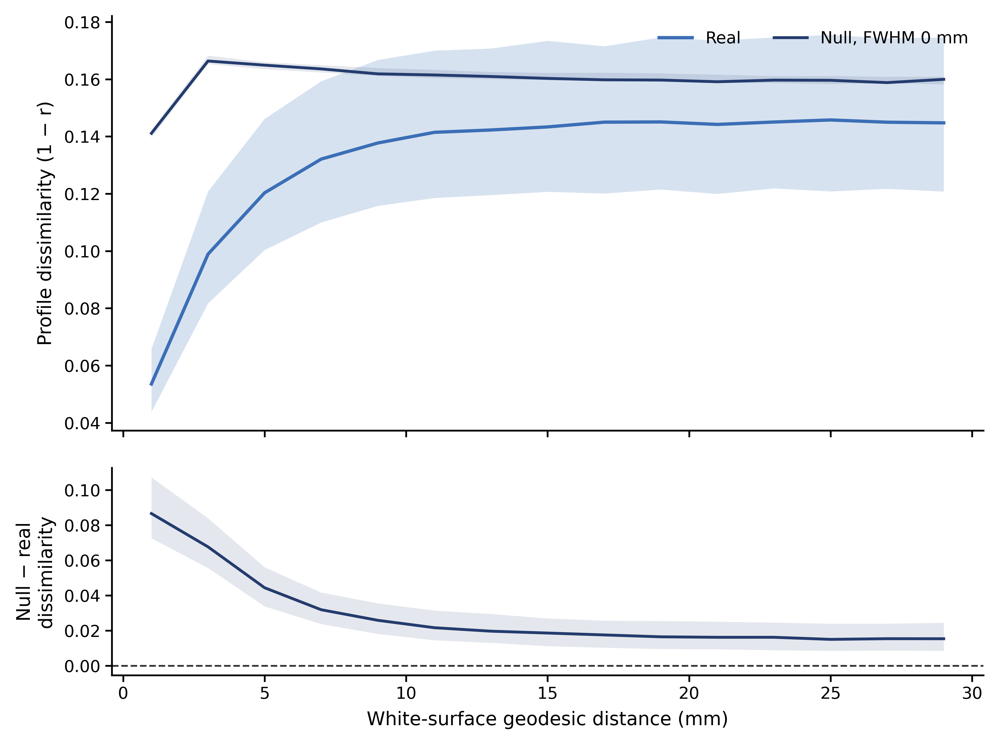

In [16]:
auc_summary = pd.read_csv(
    ACQUISITION_NULL_DIR / 'figure4B_local_excess_auc_group_summary.csv'
)
display(auc_summary)
show_image(FIGURE_DIR / 'Figure4B_acquisition_fwhm0_main_auc_supplement.png')
show_image(ACQUISITION_NULL_DIR / 'Figure4B_absolute_dissimilarity_supplement.png')

## S5. Whole-profile spatial-permutation null

Pilot sensitivity analysis in 20 subjects. Each observed 21-depth profile is kept intact while its surface location is permuted, thereby preserving the complete within-column profile and removing the observed surface arrangement.

,method,distance_bin_index,distance_bin,n_subjects,real_dissimilarity_median,real_dissimilarity_q25,real_dissimilarity_q75,null_dissimilarity_median,null_dissimilarity_q25,null_dissimilarity_q75,...,null_minus_real_q75,real_local_excess_similarity_median,real_local_excess_similarity_q25,real_local_excess_similarity_q75,null_local_excess_similarity_median,null_local_excess_similarity_q25,null_local_excess_similarity_q75,real_minus_null_local_excess_median,real_minus_null_local_excess_q25,real_minus_null_local_excess_q75
0,"DWI-grid, PSF 0 mm",0,0-2,20,0.048275,0.043693,0.062182,0.127517,0.115513,0.164670,...,0.102488,0.087391,0.072433,0.109230,0.019824,0.015870,0.022098,0.067326,0.055123,0.084740
1,"DWI-grid, PSF 0 mm",1,2-4,20,0.089734,0.077736,0.112676,0.154227,0.135870,0.198978,...,0.075882,0.046527,0.035940,0.058250,-0.006644,-0.008111,-0.005463,0.053171,0.041033,0.065575
2,"DWI-grid, PSF 0 mm",2,4-6,20,0.110972,0.099210,0.139092,0.152618,0.134578,0.196407,...,0.051050,0.021190,0.017060,0.031244,-0.005219,-0.006095,-0.004028,0.026159,0.021892,0.036051
3,"DWI-grid, PSF 0 mm",3,6-8,20,0.120858,0.106445,0.152847,0.151221,0.134078,0.194433,...,0.034455,0.012361,0.009209,0.016065,-0.003702,-0.004185,-0.003053,0.015928,0.012221,0.019602
4,"DWI-grid, PSF 0 mm",4,8-10,20,0.128321,0.111631,0.161876,0.150526,0.133210,0.192440,...,0.029244,0.006489,0.004712,0.009239,-0.002416,-0.003333,-0.002067,0.009425,0.006415,0.012261
5,"DWI-grid, PSF 0 mm",5,10-12,20,0.133010,0.112741,0.170223,0.150256,0.132843,0.192934,...,0.026542,0.003098,0.001159,0.005329,-0.002185,-0.002611,-0.001623,0.004758,0.003367,0.007911
6,"DWI-grid, PSF 0 mm",6,12-14,20,0.133978,0.114070,0.171138,0.149140,0.132467,0.192261,...,0.022065,0.001781,0.000327,0.003016,-0.001457,-0.001814,-0.001172,0.003319,0.001570,0.005005
7,"DWI-grid, PSF 0 mm",7,14-16,20,0.134172,0.115485,0.174574,0.149084,0.131943,0.191100,...,0.022840,0.001748,-0.000938,0.003015,-0.001063,-0.001428,-0.000806,0.002645,0.000763,0.004151
8,"DWI-grid, PSF 0 mm",8,16-18,20,0.136607,0.116937,0.172159,0.148369,0.131818,0.190472,...,0.020503,0.000521,-0.000706,0.002003,-0.000743,-0.000987,-0.000424,0.001141,-0.000380,0.003074
9,"DWI-grid, PSF 0 mm",9,18-20,20,0.133994,0.116473,0.172807,0.148526,0.131906,0.189910,...,0.021741,0.000392,-0.001211,0.001224,-0.000787,-0.000996,-0.000494,0.000928,-0.000138,0.001494


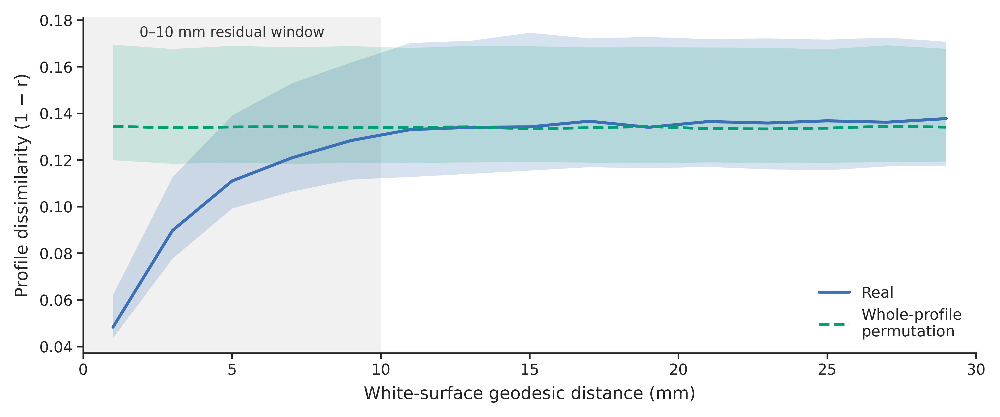

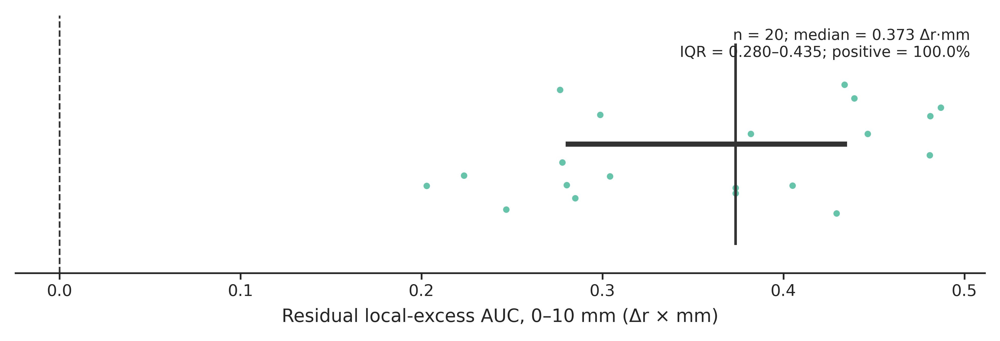

In [17]:
permutation_summary = pd.read_csv(
    WHOLE_PROFILE_NULL_DIR / 'figure4B_null_comparison_group_summary.csv'
)
display(permutation_summary)
show_image(FIGURE_DIR / 'Figure4B_whole_profile_permutation_pilot20.png')
show_image(FIGURE_DIR / 'Figure4B_whole_profile_permutation_pilot20_auc_supplement.png')

## S6. Reference-platform and common-profile validation

Sparse long-range pairs test whether 20–30 mm is a defensible reference plateau. The laminar-shape diagnostic quantifies the common subject-level profile component that keeps absolute correlations high even at long distances.

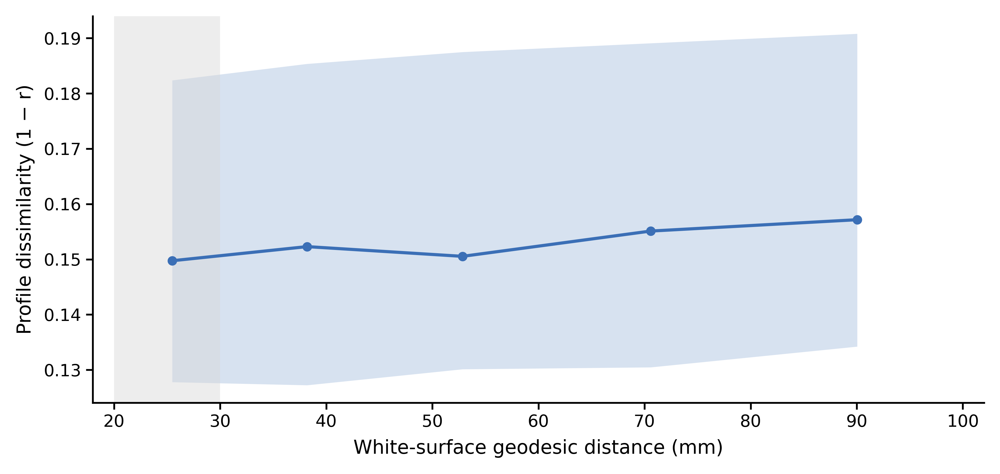

,distance_bin_index,distance_bin,median_distance_mm,dissimilarity_median,dissimilarity_q25,dissimilarity_q75,n_subjects,anchor_count_total,pair_count_total
0,0,20-30,25.484080,0.149734,0.127791,0.182369,325,161677,1598855
1,1,30-45,38.194768,0.152288,0.127234,0.185344,325,161674,1597030
2,2,45-60,52.848720,0.150531,0.130125,0.187483,325,161670,1597764
3,3,60-80,70.583462,0.155102,0.130470,0.189077,325,161669,1599094
4,4,80-100,90.043922,0.157154,0.134219,0.190789,325,161673,1597306


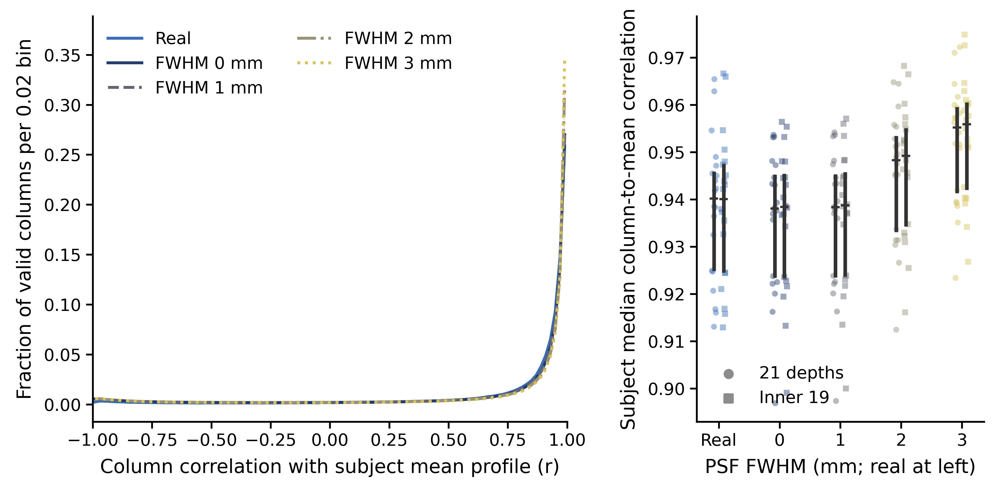

,condition,depth_set,n_subjects,median,q25,q75,bootstrap_ci_low,bootstrap_ci_high
0,FWHM 0 mm,all_21_depths,20,0.938089,0.923449,0.945272,0.929735,0.943954
1,FWHM 0 mm,inner_19_depths,20,0.938410,0.923352,0.945464,0.928926,0.944559
2,FWHM 1 mm,all_21_depths,20,0.938368,0.923529,0.945309,0.929924,0.943998
3,FWHM 1 mm,inner_19_depths,20,0.938730,0.923687,0.945773,0.929308,0.944800
4,FWHM 2 mm,all_21_depths,20,0.948272,0.933108,0.953461,0.939368,0.952223
5,FWHM 2 mm,inner_19_depths,20,0.949196,0.934297,0.955077,0.939706,0.953708
6,FWHM 3 mm,all_21_depths,20,0.955181,0.941333,0.959521,0.946389,0.958796
7,FWHM 3 mm,inner_19_depths,20,0.955895,0.942031,0.960519,0.946779,0.960173
8,Real,all_21_depths,20,0.940176,0.924868,0.945898,0.928704,0.945489
9,Real,inner_19_depths,20,0.940067,0.924508,0.947542,0.928576,0.946236


In [18]:
show_image(LONG_RANGE_DIR / 'Figure4_long_range_platform_validation.png')
display(pd.read_csv(LONG_RANGE_DIR / 'figure4_long_range_group_summary.csv'))
show_image(LAMINAR_SHAPE_DIR / 'Figure4_common_laminar_shape_supplement.png')
display(pd.read_csv(LAMINAR_SHAPE_DIR / 'figure4_common_laminar_shape_group_summary.csv'))

## S7. DK-boundary sensitivity and coverage

The same-anchor boundary-adjacent comparison is retained as a sensitivity analysis. Region-level coverage and extreme-region diagnostics show where parcel geometry or changing comparator composition limits interpretation.

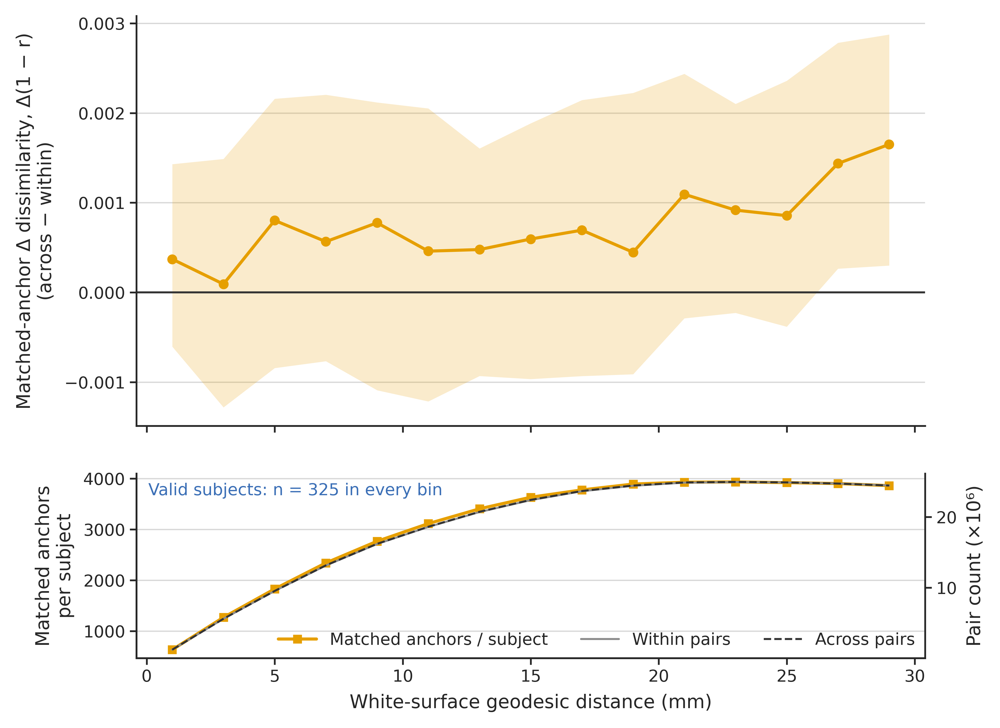

,distance_bin_index,distance_bin,n_subjects,delta_group_median,delta_q25,delta_q75,matched_anchor_count_total,matched_anchor_count_median_subject,within_pair_count_total,across_pair_count_total,within_distance_median,across_distance_median,absolute_distance_difference_mm,delta_bootstrap_ci95_low,delta_bootstrap_ci95_high
0,0,0-2,325,0.000371,-0.000604,0.001430,204553,633.0,1227429.0,1227381.0,1.585850,1.609855,0.023702,0.000107,0.000653
1,1,2-4,325,0.000092,-0.001281,0.001489,410080,1269.0,5599788.0,5601015.0,3.168244,3.174207,0.005893,-0.000162,0.000315
2,2,4-6,325,0.000803,-0.000843,0.002160,590772,1828.0,9530606.0,9534391.0,5.036069,5.041634,0.005455,0.000594,0.001192
3,3,6-8,325,0.000566,-0.000766,0.002204,756166,2340.0,13137031.0,13152920.0,7.017741,7.021291,0.003714,0.000271,0.000809
4,4,8-10,325,0.000776,-0.001090,0.002118,894112,2766.0,16175406.0,16200784.0,9.011956,9.013548,0.001611,0.000346,0.001029
5,5,10-12,325,0.000460,-0.001215,0.002052,1005820,3113.0,18584774.0,18616178.0,11.006218,11.009387,0.003170,0.000094,0.000776
6,6,12-14,325,0.000478,-0.000932,0.001605,1100033,3404.0,20694952.0,20734267.0,13.006074,13.006835,0.000862,0.000206,0.000689
7,7,14-16,325,0.000595,-0.000966,0.001886,1173830,3632.0,22378827.0,22416425.0,15.004286,15.003791,0.000502,0.000232,0.000866
8,8,16-18,325,0.000694,-0.000932,0.002145,1220329,3776.0,23638197.0,23669348.0,17.002273,17.005191,0.002881,0.000266,0.000975
9,9,18-20,325,0.000447,-0.000912,0.002225,1257537,3891.0,24410460.0,24444676.0,19.002082,19.002342,0.000333,0.000211,0.000660


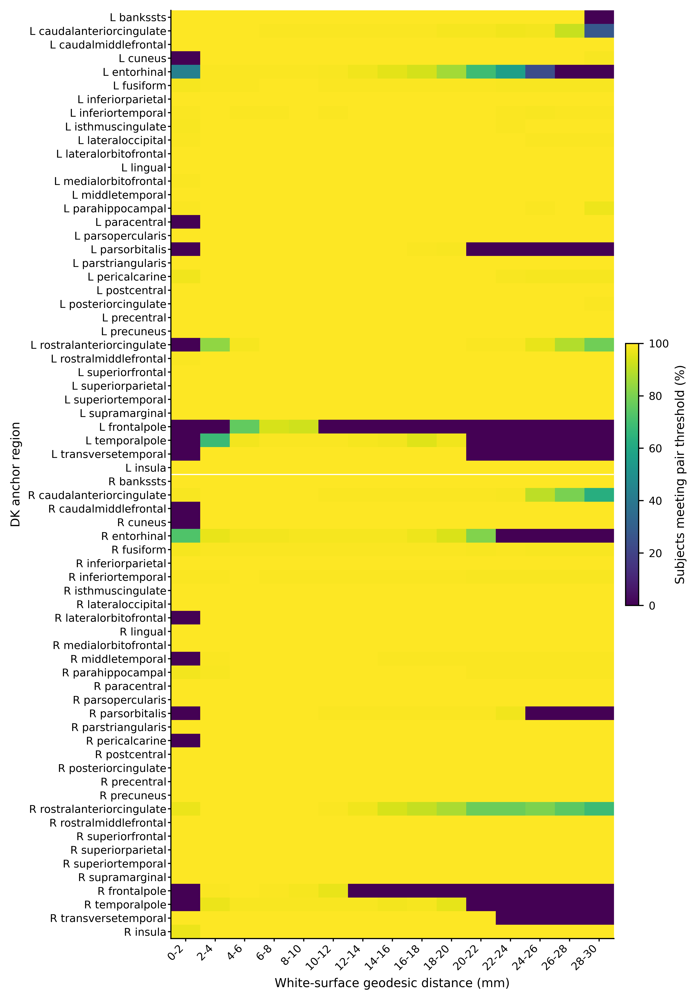

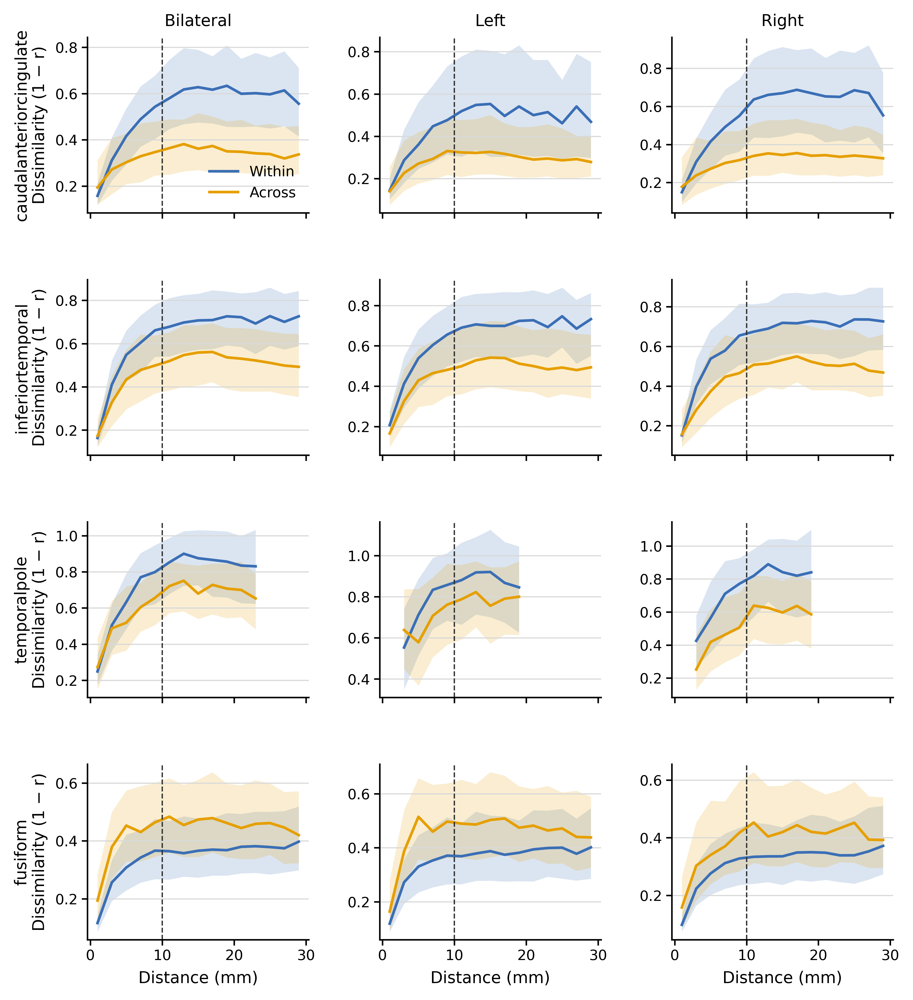

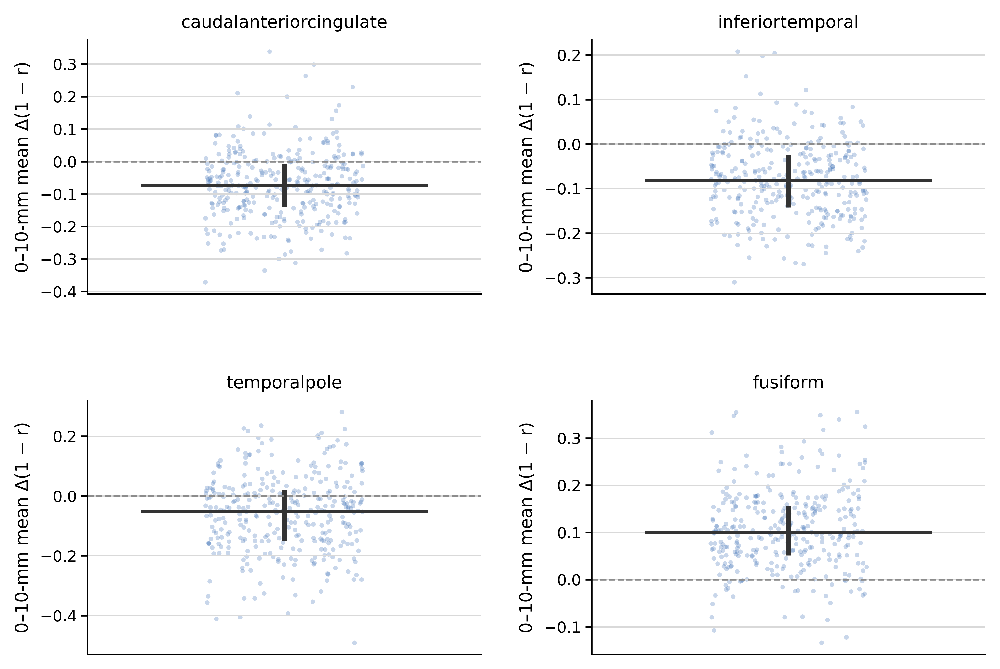

In [19]:
show_image(FIGURE_DIR / 'figure4_matched_across_minus_within_by_distance.png')
boundary = pd.read_csv(REAL_DIR / 'figure4_within_across_matched_group_summary.csv')
display(boundary)
show_image(FIGURE_DIR / 'Figure4D_region_distance_coverage_heatmap.png')
show_image(FIGURE_DIR / 'Figure4D_extreme_regions_within_across.png')
show_image(FIGURE_DIR / 'Figure4D_extreme_regions_subject_distributions.png')

## S8. ico5 within-region neighbour-number convergence

This pilot determines how many full-resolution, same-DK neighbours are needed per official ico5 anchor and 2-mm geodesic-distance bin. The official 10,242-vertex-per-hemisphere fsaverage5 sphere is mapped one-to-one to full-resolution fsaverage; the existing cortical analysis mask is then applied. For each of 10 random seeds, sampling is nested so that $P_1\subset P_3\subset P_5\subset P_{10}\subset P_{15}\subset P_{20}\subset P_{25}\subset P_{30}$. Existing ranks 1–10 are retained exactly and only ranks 11–30 are appended. The same 20 subjects used in the acquisition-null pilot are analysed using the hierarchy pair $\rightarrow$ anchor × bin median $\rightarrow$ bilateral subject or DK-region median $\rightarrow$ group summary. The current priority analysis reports $K=1,3,5,10,15,20,25$ with $K=25$ as a provisional high-$K$ reference; $K=30$ remains a later sensitivity reference rather than ground truth. Selection uses real profiles only and therefore is independent of the real–null effect.

The diagnostics report candidate-neighbour coverage, $D=1-r$, MAE and symmetric relative MAE (sRMAE). Figure K1 compares the group curves, Figure K2 shows $D_K-D_{K_{ref}}$ with the ±0.002 tolerance, and Figure K3 shows the bilateral region × distance-bin fraction of anchors having at least three candidates. Median, 95th-percentile and maximum absolute differences, seed SD/IQR, subject and region rank stability, and the analysis restricted to anchor-bins with at least 20 candidates are saved alongside the figures.

**Result shown: 20-subject priority K=1,3,5,10,15,20,25 convergence pilot. Reference K: 25; selected K: None.** K=25 is retained as the current high-K sensitivity reference because nominal-K coverage decreases substantially at short distances. Final K selection requires joint review of effective-K curves, per-bin coverage, and the n_candidates>=20 and >=30 restricted diagnostics; no automatic selection is made from the unrestricted maximum or seed metric alone.

,hemisphere,valid_ico5_anchors,dk_regions,maximum_mapping_error_degrees
0,lh,9372,34,0.0
1,rh,9370,34,0.0


,distance_bin_index,distance_bin,region_median_fraction_at_least_1,region_median_fraction_at_least_3,region_median_fraction_at_least_5,region_median_fraction_at_least_10,region_median_fraction_at_least_15,region_median_fraction_at_least_20,region_median_fraction_at_least_25
0,0,0-2,1.0,1.0,1.0,0.995284,0.941942,0.699936,0.398182
1,1,2-4,1.0,1.0,1.0,1.000000,1.000000,1.000000,0.994664
2,2,4-6,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000
3,3,6-8,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000
4,4,8-10,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000
5,5,10-12,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000
6,6,12-14,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000
7,7,14-16,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000
8,8,16-18,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000
9,9,18-20,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.000000


,k,worst_group_curve_difference,minimum_subject_spearman,minimum_subject_icc,minimum_median_region_spearman,maximum_seed_curve_range
0,1,0.033005,0.990977,0.986180,0.983957,0.005374
1,3,0.021359,0.990977,0.991270,0.989763,0.004023
2,5,0.014604,0.990977,0.995493,0.993736,0.003882
3,10,0.011029,0.990977,0.997199,0.995264,0.003064
4,15,0.004011,0.990977,0.999679,0.997097,0.001809
5,20,0.003002,0.993985,0.999828,0.998014,0.002082
6,25,0.000000,1.000000,1.000000,1.000000,0.002421


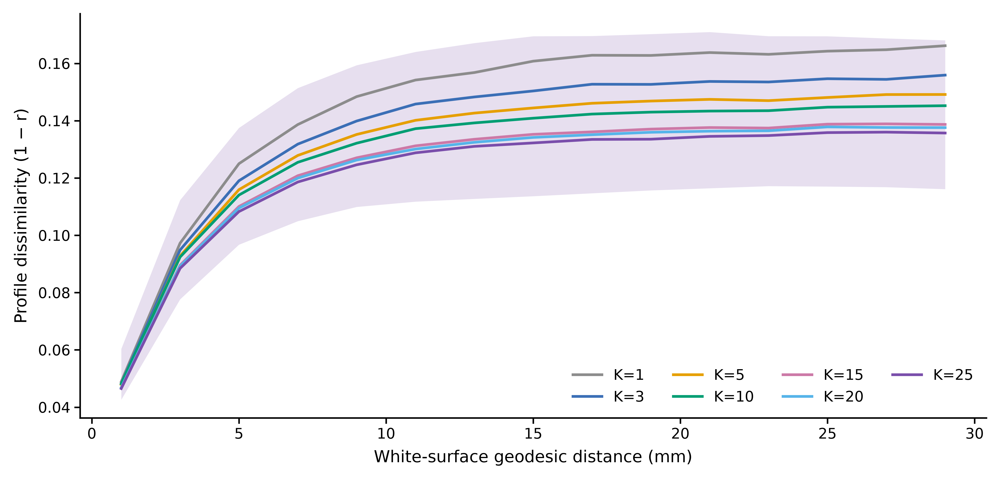

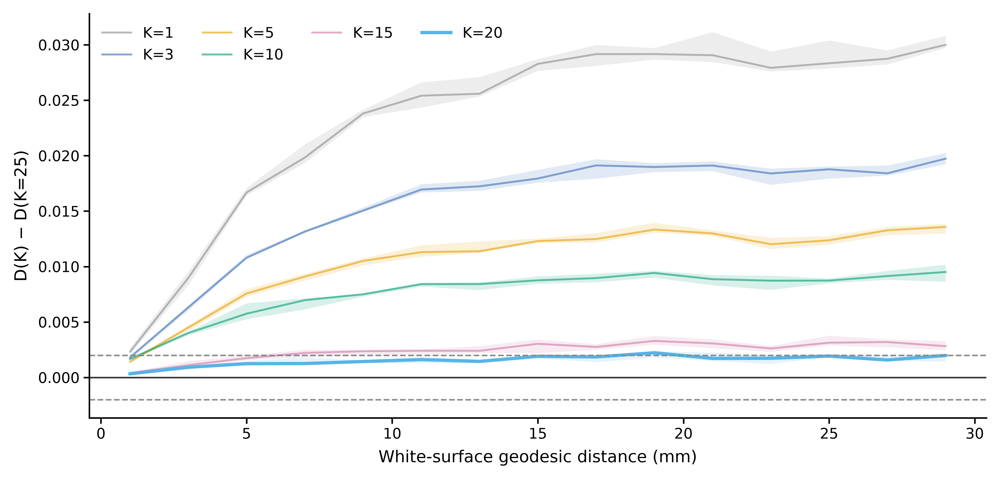

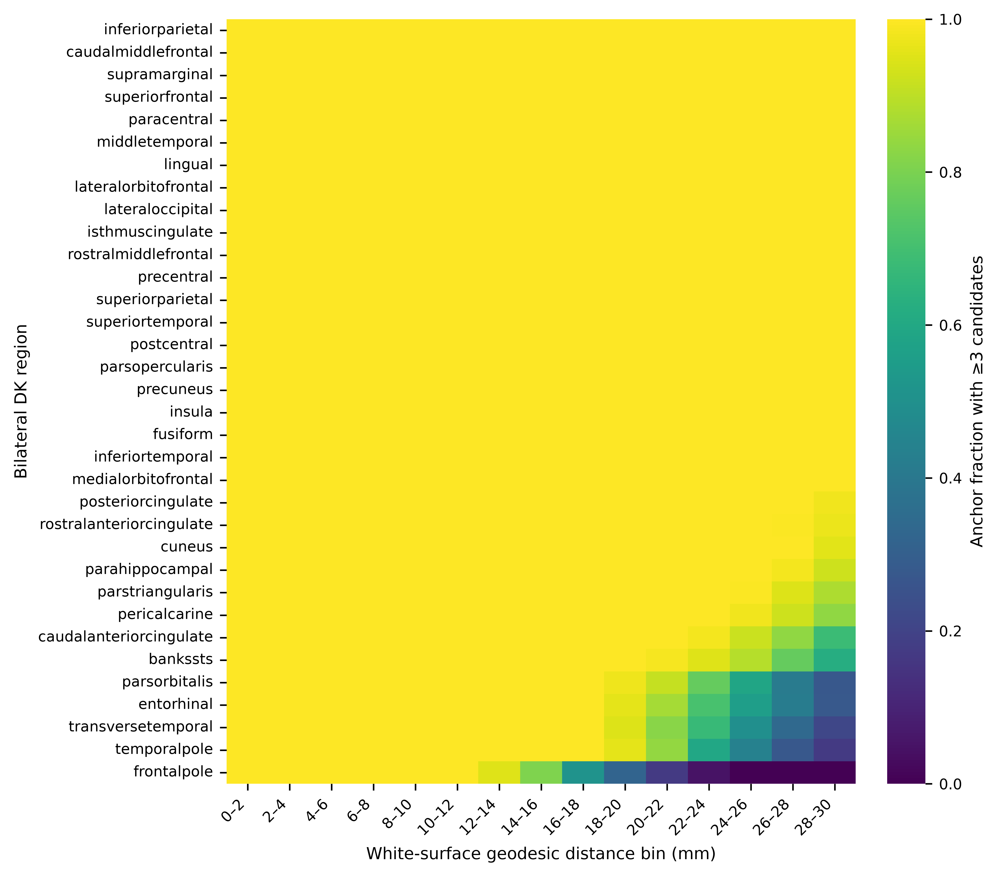

In [23]:
k30_decision_path = ICO5_K30_DIR / 'k_convergence_decision.json'
k25_decision_path = ICO5_K25_DIR / 'k_convergence_decision.json'
k20_decision_path = ICO5_K20_DIR / 'k_convergence_decision.json'
full_decision_path = ICO5_K_DIR / 'k_convergence_decision.json'
pilot5_decision_path = ICO5_K_PILOT5_DIR / 'k_convergence_decision.json'
mapping_path = ICO5_K_PAIR_DIR / 'ico5_anchor_mapping.csv'
build_path = ICO5_K_PAIR_DIR / 'ico5_pair_build.json'

if k30_decision_path.is_file():
    result_dir = ICO5_K30_DIR
    result_label = '20-subject extended K=1,3,5,10,15,20,25,30 convergence pilot'
elif k25_decision_path.is_file():
    result_dir = ICO5_K25_DIR
    result_label = '20-subject priority K=1,3,5,10,15,20,25 convergence pilot'
elif k20_decision_path.is_file():
    result_dir = ICO5_K20_DIR
    result_label = '20-subject extended K=1,3,5,10,15,20 convergence pilot'
elif full_decision_path.is_file():
    result_dir = ICO5_K_DIR
    result_label = '20-subject K-convergence pilot'
elif pilot5_decision_path.is_file():
    result_dir = ICO5_K_PILOT5_DIR
    result_label = 'preliminary first-5-subject checkpoint'
else:
    result_dir = None

if result_dir is None:
    status = 'neighbourhood construction in progress'
    if build_path.is_file():
        status = 'neighbourhood construction complete; 20-subject K pilot or summary pending'
    display(Markdown(
        f'**ico5 K-convergence status:** {status}.  '
        'This section will load the cached results automatically after the dependent jobs finish.'
    ))
else:
    decision_path = result_dir / 'k_convergence_decision.json'
    coverage_path = result_dir / 'k_convergence_coverage.csv'
    stability_path = result_dir / 'k_convergence_stability.csv'
    decision = json.loads(decision_path.read_text())
    mapping = pd.read_csv(mapping_path)
    coverage = pd.read_csv(coverage_path)
    stability = pd.read_csv(stability_path)

    anchor_inventory = (
        mapping.groupby('hemisphere', as_index=False)
        .agg(
            valid_ico5_anchors=('ico5_vertex_id', 'nunique'),
            dk_regions=('dk_region', 'nunique'),
            maximum_mapping_error_degrees=(
                'angular_mapping_error_degrees', 'max'
            ),
        )
    )
    display(Markdown(
        f"**Result shown: {result_label}. Reference K: {decision['reference_k']}; "
        f"selected K: {decision['selected_k']}.** "
        f"{decision['decision_reason']}"
    ))
    display(anchor_inventory)

    available_k = sorted(stability['k'].astype(int).unique())
    coverage_columns = [
        f'fraction_at_least_{k}' for k in available_k
        if f'fraction_at_least_{k}' in coverage.columns
    ]
    coverage_by_bin = (
        coverage.groupby(['distance_bin_index', 'distance_bin'], as_index=False)[coverage_columns]
        .median()
        .rename(columns={name: f'region_median_{name}' for name in coverage_columns})
        .sort_values('distance_bin_index')
    )
    display(coverage_by_bin)

    primary_stability = stability.loc[
        stability['metric'].eq('profile_dissimilarity')
        & stability['k'].isin(available_k)
    ]
    stability_across_seeds = (
        primary_stability.groupby('k', as_index=False)
        .agg(
            worst_group_curve_difference=(
                'curve_maximum_absolute_difference', 'max'
            ),
            minimum_subject_spearman=('subject_spearman_rho', 'min'),
            minimum_subject_icc=('subject_icc_two_way_single', 'min'),
            minimum_median_region_spearman=(
                'region_spearman_median_subject', 'min'
            ),
            maximum_seed_curve_range=(
                'maximum_seed_to_seed_curve_difference', 'max'
            ),
        )
    )
    display(stability_across_seeds)

    for figure_name in (
        'FigureK1_curves.png',
        (
            'FigureK2_difference_from_k25.png'
            if (result_dir / 'FigureK2_difference_from_k25.png').is_file()
            else (
                'FigureK2_difference_from_k30.png'
                if (result_dir / 'FigureK2_difference_from_k30.png').is_file()
                else (
                    'FigureK2_difference_from_k20.png'
                    if (result_dir / 'FigureK2_difference_from_k20.png').is_file()
                    else 'FigureK2_difference_from_k10.png'
                )
            )
        ),
        'FigureK3_k3_coverage.png',
    ):
        show_image(result_dir / figure_name)